In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

# 1. Load Dataset

In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion')
emotion_dataset

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [ ]:
emotion_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [ ]:
df = pd.DataFrame(emotion_dataset["train"])
df_val = pd.DataFrame(emotion_dataset["validation"])
df_test = pd.DataFrame(emotion_dataset["test"])

In [ ]:
df.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


In [ ]:
label_names = emotion_dataset['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
df['label'] = [label_names[i] for i in df['label']]
df_val['label'] = [label_names[i] for i in df_val['label']]
df_test['label'] = [label_names[i] for i in df_test['label']]

In [ ]:
df.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df.isnull().sum()

,0
text,0
label,0


In [ ]:
df.duplicated().sum()

np.int64(1)

# 2. EDA

In [ ]:
df['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

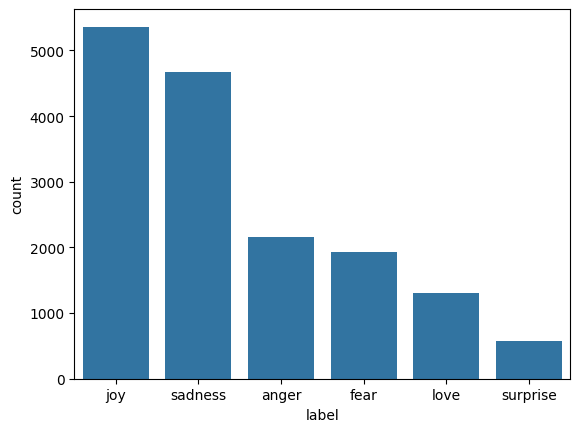

In [ ]:
sns.countplot(data=df, x="label", order = df['label'].value_counts().index)

# 3. Preprocessing

In [ ]:
# Assign class weights to handle imbalance
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(df['label']),
    y = df['label']
)

class_weight_dict = dict(enumerate(class_weights))
class_weight_dict

{0: np.float64(1.2351397251814111),
 1: np.float64(1.3766993632765445),
 2: np.float64(0.49732686808404825),
 3: np.float64(2.044989775051125),
 4: np.float64(0.5715102157451064),
 5: np.float64(4.662004662004662)}

In [ ]:
# Tokenize text, add padding
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

vectorizer = TextVectorization(
    max_tokens=max_words,
    output_mode="int",
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_sequence_length=66
)

vectorizer.adapt(df['text'].astype(str).values)

train_sequence = vectorizer(
    df["text"].astype(str).values
).numpy()

test_sequence = vectorizer(
    df_test["text"].astype(str).values
).numpy()

val_sequence = vectorizer(
    df_val["text"].astype(str).values
).numpy()

In [ ]:
train_labels = np.array(emotion_dataset['train']['label'])
val_labels = np.array(emotion_dataset['validation']['label'])
test_labels = np.array(emotion_dataset['test']['label'])

In [ ]:
num_classes = len(np.unique(train_labels))

In [ ]:
vocab_size = len(vectorizer.get_vocabulary())
print(f"Vocab size: {vocab_size}")
print(f"Max Length: {len(train_sequence[1])}")

Vocab size: 10000
Max Length: 66


In [ ]:
# Early Stopping
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor = "val_loss",
    patience = 5,
    restore_best_weights = True
)

# 4. Train Base Models

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, SimpleRNN, LSTM, GRU

## 4.1 Model 1 - Simple RNN

In [ ]:
rnn_model = Sequential([
    Embedding(input_dim = vocab_size, output_dim=128),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
rnn_model.fit(
    train_sequence,
    train_labels,
    batch_size=32,
    epochs=20,
    validation_data=(val_sequence, val_labels),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.2871 - loss: 2.2832 - val_accuracy: 0.3520 - val_loss: 1.6611
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.3234 - loss: 2.1627 - val_accuracy: 0.3510 - val_loss: 1.6966
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.3319 - loss: 2.1482 - val_accuracy: 0.3520 - val_loss: 1.6927
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.3304 - loss: 2.1435 - val_accuracy: 0.3480 - val_loss: 1.6739
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.3329 - loss: 2.1361 - val_accuracy: 0.3480 - val_loss: 1.7078
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.3030 - loss: 2.2126 - val_accuracy: 0.3430 - val_loss: 1.7591


## 4.2 Model 2 - LSTM


In [ ]:
lstm_model = Sequential([
    Embedding(input_dim = vocab_size, output_dim=128),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

lstm_model.fit(
    train_sequence,
    train_labels,
    batch_size=32,
    epochs=20,
    validation_data=(val_sequence, val_labels),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.3138 - loss: 2.1734 - val_accuracy: 0.3520 - val_loss: 1.6612
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.3327 - loss: 2.1504 - val_accuracy: 0.3520 - val_loss: 1.6856
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.3336 - loss: 2.1411 - val_accuracy: 0.3505 - val_loss: 1.6918
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3334 - loss: 2.1416 - val_accuracy: 0.3510 - val_loss: 1.6862
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.3347 - loss: 2.1399 - val_accuracy: 0.3515 - val_loss: 1.6819


## 4.3 Model 3 - GRU

In [ ]:
gru_model = Sequential([
    Embedding(input_dim = vocab_size, output_dim=128),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

gru_model.fit(
    train_sequence,
    train_labels,
    batch_size=32,
    epochs=20,
    validation_data=(val_sequence, val_labels),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.3225 - loss: 2.1614 - val_accuracy: 0.3520 - val_loss: 1.6948
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3314 - loss: 2.1427 - val_accuracy: 0.3520 - val_loss: 1.6953
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3329 - loss: 2.1427 - val_accuracy: 0.3520 - val_loss: 1.7094
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.3344 - loss: 2.1399 - val_accuracy: 0.3520 - val_loss: 1.6780
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.3346 - loss: 2.1378 - val_accuracy: 0.3520 - val_loss: 1.6888


## 4.4 Evaluation

In [ ]:
# Evaliuate RNN
rnn_loss, rnn_accuracy = rnn_model.evaluate(test_sequence, test_labels)
lstm_loss, lstm_accuracy = lstm_model.evaluate(test_sequence, test_labels)
gru_loss, gru_accuracy = gru_model.evaluate(test_sequence, test_labels)

model_scores = {
    "Simple RNN": (rnn_loss, rnn_accuracy),
    "LSTM": (lstm_loss, lstm_accuracy),
    "GRU": (gru_loss, gru_accuracy),
}

for name, scores in model_scores.items():
  print(name)
  print(f"Loss: {scores[0]}")
  print(f"Accuracy: {scores[1]}")
  print()

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3460 - loss: 1.6489
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3475 - loss: 1.6452
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3475 - loss: 1.6781
Simple RNN
Loss: 1.6489146947860718
Accuracy: 0.34599998593330383

LSTM
Loss: 1.6451609134674072
Accuracy: 0.3474999964237213

GRU
Loss: 1.6780973672866821
Accuracy: 0.3474999964237213



In [ ]:
scores_df = pd.DataFrame(model_scores, index=["Loss", "Accuracy"]).T.sort_values(by="Accuracy", ascending=False)
scores_df

,Loss,Accuracy
LSTM,1.645161,0.3475
GRU,1.678097,0.3475
Simple RNN,1.648915,0.3460


## 4.5 Bidirectional - GRU
We choose GRU as its giving same accuracy as LSTM and is computationally less expensive

In [ ]:
from tensorflow.keras.layers import Bidirectional

In [ ]:
Bi_GRU = Sequential([
    Embedding(input_dim=vocab_size, output_dim=300),
    Bidirectional(GRU(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

Bi_GRU.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=['accuracy'])

In [ ]:
Bi_GRU.fit(
    train_sequence,
    train_labels,
    batch_size=32,
    epochs=20,
    verbose=1,
    callbacks=[early_stopping],
    validation_data=(val_sequence, val_labels),
    class_weight = class_weight_dict,
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.6157 - loss: 1.2319 - val_accuracy: 0.8645 - val_loss: 0.4390
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9096 - loss: 0.2594 - val_accuracy: 0.9255 - val_loss: 0.2297
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9463 - loss: 0.1462 - val_accuracy: 0.9245 - val_loss: 0.2112
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9601 - loss: 0.1088 - val_accuracy: 0.9260 - val_loss: 0.2397
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9680 - loss: 0.0914 - val_accuracy: 0.9255 - val_loss: 0.2605
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9748 - loss: 0.0713 - val_accuracy: 0.9215 - val_loss: 0.3099
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9780 - loss: 0.0609 - val_accuracy: 0.9195 - val_loss: 0.3137
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9796 - loss: 0.0607 - val_a

In [ ]:
bigru_loss, bigru_accuracy = Bi_GRU.evaluate(test_sequence, test_labels)
print(f"Loss: {bigru_loss}")
print(f"Accuracy: {bigru_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9180 - loss: 0.2240
Loss: 0.22395066916942596
Accuracy: 0.9179999828338623


#5. Final model confusion matrix

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


<Axes: >

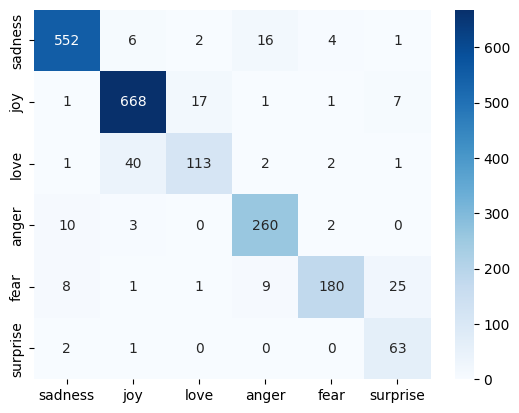

In [ ]:
from sklearn.metrics import confusion_matrix

Bi_GRU_predictions = np.argmax(Bi_GRU.predict(test_sequence), axis=1)

sns.heatmap(confusion_matrix(test_labels, Bi_GRU_predictions), annot=True, fmt='d', xticklabels=label_names, yticklabels=label_names, cmap='Blues')

# 6. Final prediction test

In [ ]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = vectorizer(sample_texts).numpy()

sample_pred = np.argmax(Bi_GRU.predict(sample_sequences), axis=1)

for i in range(len(sample_pred)):
  print(sample_texts[i])
  print(label_names[sample_pred[i]])
  print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
I can't believe how happy I am right now, this is amazing!
joy

I feel so alone and hopeless today.
sadness

I am furious that they cancelled the trip at the last minute.
anger

I feel terrified when walking down dark alleyways alone.
fear

I was shocked and completely surprised by the unexpected gift!
surprise



# Save model

In [ ]:
import os
import pickle

Bi_GRU.save("BiGRU_model.keras")
with open("vectorizer.pkl", "wb") as f:
  pickle.dump(vectorizer, f)